<a href="https://colab.research.google.com/github/jeyner99/Integracion-de-datos-y-prospectiva/blob/main/Reto_parcial_ll_Jeyner_Casta%C3%B1o_Ocampo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import scipy.stats as stats
warnings.filterwarnings('ignore')

In [ ]:
def clusterizacion(X):
    # Proceso de Clusterización
    XC = np.random.choice(X, size=5)
    XC = np.sort(XC).astype(float) # Semillas de la Clusterización
                                   # Corregido: float para que la actualización (XC + X)/2 no se trunque si X es entero
    nc = np.zeros((len(X), 5)) # Aquí clasifico los datos en cada una de las semillas

    for k in range(len(X)):
        d = np.abs(XC - X[k]) # Distancia de un dato a cada semilla
        nc[k] = np.argmin(d)
        nc2 = np.int32(nc[k][0]) # Número de pertenencia al cluster en enteros
        XC[nc2] = (XC[nc2] + X[k]) / 2 # Actualizamos la semilla a la que pertenece cada dato (x_k)

    return XC, nc # Nos retorna clusters y cluster al que pertenece un dato

In [ ]:
np.random.seed(42)
mxl = '/content/drive/MyDrive/Universidad/2026-2/Integración de datos y prospectiva/1. RiesgoOperacional_EVERGREEEN.xlsx'
XD0 = pd.read_excel(mxl, sheet_name=0)
XD0 = XD0.dropna().reset_index(drop=True) # Elimina el tema de datos faltantes

Xf = np.array(XD0.iloc[:, 3])  # Número de eventos de riesgo
Xs = np.array(XD0.iloc[:, 4]) # Severidad de los eventos

# Buscamos los Fuzzy Sets Xf
XCf, ncf = clusterizacion(Xf) # XCf: Indica los concentradores de información - ncf: Cluster Pertenence
lbf = ['MuyPocoFrecuente', 'PocoFrecuente', 'Normal', 'Frecuente', 'MuyFrecuente']

XCs, ncs = clusterizacion(Xs)
lbs = ['Insignif', 'Menor', 'Significativo', 'Mayor', 'Severo']

sigmaf = []
sigmas = [] # Bases para la variable

for i in range(5):
    sigmaf.append(np.sqrt((np.sum((XCf - XCf[i])**2) / 4)))
    sigmas.append(np.sqrt((np.sum((XCs - XCs[i])**2) / 4)))

print("Los clusters de frecuencia son:", XCf)
print("Los clusters de Costo-Atención (Severidad):", XCs)

Los clusters de frecuencia son: [ 4.17044959 20.95541735 31.97463224 55.3989771  47.48569206]
Los clusters de Costo-Atención (Severidad): [ 3.51438945 15.64305456 22.23442867 40.87993454 70.43382636]


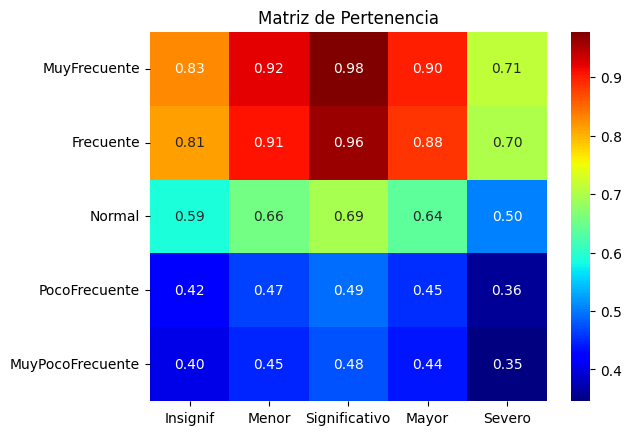

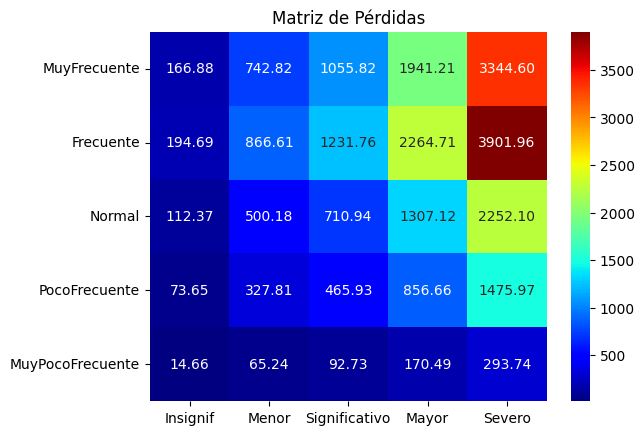

El costo de este paciente al año es: 1366.11679246
El costo real de este paciente es: 1081.3872443260034


In [ ]:
# Definimos un paciente de prueba para los cálculos de costo tradicional
Xfp = 49  # Frecuencia representativa (ejemplo: 49 eventos de riesgo)
Xsp = 27.87993454  # Severidad representativa (ejemplo: severidad de 27.87993454)

# Calculamos la Matriz de Pertenencia (MVP) usando una función gaussiana
# para cada combinación de las 5 categorías de frecuencia y severidad.
MVP = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        # Evaluamos la pertenencia del paciente de prueba a los clusters
        pert_f = np.exp(-0.5 * ((Xfp - XCf[i]) / sigmaf[i])**2) if sigmaf[i] > 0 else 0
        pert_s = np.exp(-0.5 * ((Xsp - XCs[j]) / sigmas[j])**2) if sigmas[j] > 0 else 0
        # La pertenencia conjunta (intersección) se suele modelar como el producto
        MVP[i, j] = pert_f * pert_s

# Visualización de Matriz de Pertenencia
plt.figure()
# Solo visualización: se voltean las filas para que el riesgo más alto quede arriba a la derecha
sns.heatmap(np.flipud(MVP), annot=True, fmt='.2f', cmap='jet', xticklabels=lbs, yticklabels=lbf[::-1])
plt.title('Matriz de Pertenencia')
plt.show()

# Construimos la Matriz de Pérdida
MP = np.outer(XCf, XCs)

plt.figure()
sns.heatmap(np.flipud(MP), annot=True, fmt='.2f', cmap='jet', xticklabels=lbs, yticklabels=lbf[::-1])
plt.title('Matriz de Pérdidas')
plt.show()

# ¿Cuánto es el costo normal de la atención a un evento de riesgo?
# Multiplicación Simple
LDA = Xfp * Xsp
print("El costo de este paciente al año es:", LDA)

# ¿Cuánto es el costo del evento de riesgo teniendo en cuenta distribuciones?
# Convolución - Carga con la estructura de las distribuciones
LDAm = np.sum(MVP * MP) / np.sum(MVP) if np.sum(MVP) > 0 else 0
print("El costo real de este paciente es:", LDAm)

# Clasificamos pacientes por frecuencia (fila) - severidad (columna)
ME = np.zeros((5, 5))
for k in range(len(XD0)):
    # Tomamos el índice de pertenencia de cada dato
    fila = int(ncf[k][0])
    columna = int(ncs[k][0])
    ME[fila, columna] = ME[fila, columna] + 1

In [ ]:
# Potencial de captura
VCF = (LDA - LDAm)*1000 # Cuanta plata me ahorro por este evento de riesgo gestionándolo con todos los demás
print("El valor financiero capturado es:", VCF)

CTCO2 = 90 # Costo de tonelada capturada
GEI = (VCF / CTCO2) #Multiplicado por mil porque las cifras están en miles de dólares.
print("La cantidad de toneladas capturadas en este evento de riesgo es:", GEI)

El valor financiero capturado es: 284729.54813399655
La cantidad de toneladas capturadas en este evento de riesgo es: 3163.661645933295


In [ ]:
NG = float(input("Ingresar el Nivel de Gestión "))

# Matriz de Impacto (MI) de 5x5, según la importancia de la escala de 1 a 5
MI = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        MI[i, j] = (i + j) / 2 + 1  # Nivel de impacto promedio

# Matriz de Gestión
MG = MI.copy().astype(float)
MG[(MG > 1) & (MG < 5)] *= NG # Corregido: se multiplica por NG, igual que en la celda de escenarios
print("La matriz de gestión es (riesgo alto arriba a la derecha):\n", np.flipud(MG))

ER = np.mean(MI / MG)
print("La exposición al riesgo es:", ER)

# Costo del paciente incluyendo los niveles de riesgo
LDAm4 = np.sum(MI * MP * MVP * ME) / np.sum(MVP * ME * MG)

# Valores ilustrativos
LDAm2 = LDAm * 1.1  # Valor estimado de eventos de pérdida
LDAm3 = LDAm * 1.25 # Valor estimado de nivel de impacto

# Distribución de Referencia (NG = 1 -> MG = MI) - Exposición Riesgo 100%
LDAm0 = np.sum(MI * MP * MVP * ME) / np.sum(MVP * ME * MI)

print("El costo del paciente tradicional es:", LDA)
print("El valor de referencia es (NG=1):", LDAm0)
print("El costo del paciente con matriz de Pertenencia es:", LDAm)
print("El costo del paciente con Eventos de Pérdida:", LDAm2)
print("El costo del paciente con Nivel de Impacto es:", LDAm3)
print("El costo real del paciente con Nivel de Gestión (NG) es:", LDAm4)

# Estimación de Captura de Gases de Efecto Invernadero
Vcapt = LDAm0 - LDAm4
print("El valor capturado financiero es:", Vcapt)

Ingresar el Nivel de Gestión 1.5
La matriz de gestión es (riesgo alto arriba a la derecha):
 [[4.5  5.25 6.   6.75 5.  ]
 [3.75 4.5  5.25 6.   6.75]
 [3.   3.75 4.5  5.25 6.  ]
 [2.25 3.   3.75 4.5  5.25]
 [1.   2.25 3.   3.75 4.5 ]]
La exposición al riesgo es: 0.6933333333333332
El costo del paciente tradicional es: 1366.11679246
El valor de referencia es (NG=1): 541.4379322137144
El costo del paciente con matriz de Pertenencia es: 1081.3872443260034
El costo del paciente con Eventos de Pérdida: 1189.5259687586038
El costo del paciente con Nivel de Impacto es: 1351.7340554075042
El costo real del paciente con Nivel de Gestión (NG) es: 368.49057303106065
El valor capturado financiero es: 172.9473591826537


--------------------
El nivel de gestión es: 1.0
La matriz de gestión es (riesgo alto arriba a la derecha):
 [[3.  3.5 4.  4.5 5. ]
 [2.5 3.  3.5 4.  4.5]
 [2.  2.5 3.  3.5 4. ]
 [1.5 2.  2.5 3.  3.5]
 [1.  1.5 2.  2.5 3. ]]
La exposición al riesgo es: 1.0
El número de eventos de pérdida esperados de referencia son: 1496
El coeficiente de asimetría de referencia es: 1.2517721675096543
El número de eventos de pérdida esperados gestionados son: 1496
El coeficiente de asimetría gestionado es: 1.2517721675096543
Número de eventos de pérdida movilizados: 0
El valor capturado financiero es:  0.0
El número de toneladas capturadas es:  0.0
El costo real de gestión es:  0.0
--------------------
El nivel de gestión es: 1.1
La matriz de gestión es (riesgo alto arriba a la derecha):
 [[3.3  3.85 4.4  4.95 5.  ]
 [2.75 3.3  3.85 4.4  4.95]
 [2.2  2.75 3.3  3.85 4.4 ]
 [1.65 2.2  2.75 3.3  3.85]
 [1.   1.65 2.2  2.75 3.3 ]]
La exposición al riesgo es: 0.9163636363636363
El número de eventos de pérdi

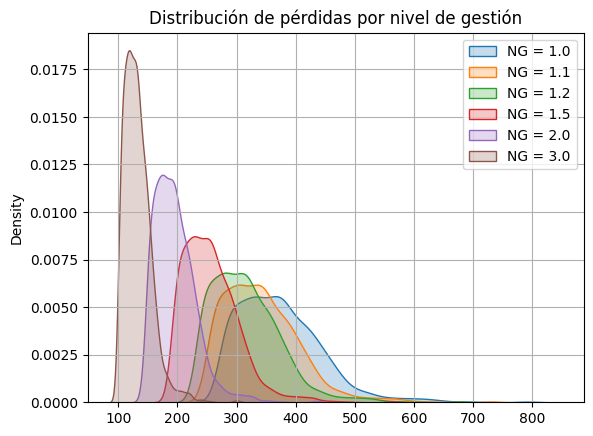

El valor capturado financiero es promedio: 240.93007891022384


In [ ]:
NG = np.array([1, 1.1, 1.2, 1.5, 2, 3]) # Incrementar el presupuesto para gestión - matriz de gestión
plt.figure()
# Convertimos sigmaf y sigmas a numpy arrays para permitir operaciones vectorizadas
sigmaf_arr = np.array(sigmaf)
sigmas_arr = np.array(sigmas)

for ng in NG:
    print("--------------------")
    print("El nivel de gestión es:", ng)

    # Creamos la matriz de gestión
    MG = MI.copy().astype(float)
    MG[(MG > 1) & (MG < 5)] *= ng

    print("La matriz de gestión es (riesgo alto arriba a la derecha):\n", np.flipud(MG))
    ER = np.mean(MI / MG)
    print("La exposición al riesgo es:", ER)

    LDAm5 = []

    for k in range(len(XD0)):
        VPf = np.exp(-0.5 * ((XCf - Xf[k]) / sigmaf_arr)**2) # Valor de Pertenencia a la Frecuencia
        VPs = np.exp(-0.5 * ((XCs - Xs[k]) / sigmas_arr)**2) # Valor de Pertenencia a la Severidad
        MVPk = np.outer(VPf, VPs) # Corregido: nombre distinto para no sobrescribir el MVP global

        LDAm5.append(np.sum(MI * MP * MVPk * ME) / np.sum(MVPk * ME * MG))

    LDAm5 = np.array(LDAm5) # Esta es la distribución pérdidas para los pacientes por nivel de gestión

    if ng == 1:
        LDAm0ref = LDAm5 # Distribución de Referencia - Exposición Riesgo 100%

    # Caracterizamos los parámetros de riesgo - Distribución de Referencia NG = 1
    um0 = np.mean(LDAm0ref) # media de la distribución
    NEL0 = len(np.where(LDAm0ref < um0)[0])
    CAS0 = stats.skew(LDAm0ref)

    print("El número de eventos de pérdida esperados de referencia son:", NEL0)
    print("El coeficiente de asimetría de referencia es:", CAS0)

    # Caracterizamos la distribución de pérdidas gestionada
    umg = np.mean(LDAm5)
    NELg = len(np.where(LDAm5 < umg)[0])
    CASg = stats.skew(LDAm5)
    print("El número de eventos de pérdida esperados gestionados son:", NELg)
    print("El coeficiente de asimetría gestionado es:", CASg)

    # Números de eventos de pérdida movilizados
    NEPm = NELg - NEL0
    print("Número de eventos de pérdida movilizados:", NEPm)

    # El ahorro que se logra con la movilización es el siguiente:
    CPerdida = np.mean(Xs) # Costo de una pérdida promedio
    VCapt = NEPm * CPerdida # Cuanto me ahorro movilizando pacientes hacia la categoría de pacientes sanos
    print("El valor capturado financiero es: ", VCapt)

    # El número total de toneladas de carbono potenciales son:
    CCO2 = 90 # USD/Ton: Me pagarían por capturar gases de efecto invernadero
    TC = VCapt / CCO2 # Toneladas de carbono que evito cuando evito que los eventos de riesgo se presenten
    print("El número de toneladas capturadas es: ", TC)

    # Cuánta plata me cuesta la gestión
    CGP = 75.92 # Esto me cuesta la atención de cada evento de riesgo
    CGT = NEPm * CGP
    print("El costo real de gestión es: ", CGT)

    sns.kdeplot(LDAm5, fill=True, label=f"NG = {ng}") # Corregido: label para que funcione plt.legend()

plt.title("Distribución de pérdidas por nivel de gestión") # Corregido: título general, no solo el último ng
plt.legend()
plt.grid()
plt.show()

Vcapt = LDAm0ref - LDAm5 # Corregido: se compara contra la distribución de referencia, no el escalar LDAm0
print("El valor capturado financiero es promedio:", np.mean(Vcapt))

#Análisis de resultados:

La lógica borrosa (Fuzzy Logic) nos ayuda a identificar el verdadero costo de darle o no tratamiento a un riesgo, porque utiliza los valores de pertenencia de un evento de riesgo dentro de una matriz para calcular el valor de atender el riesgo y no lo calcula simplemente ubicandolo en un solo valor.

En el caso de Evergreen el evento de riesgo que estamos tratando es relacionado al modelo de negocio de Evergreen y a los contenedores que entrega, este riesgo puede tener diferentes impactos, siendo los más graves los incidentes en el mar, como contaminación, colisiones o encallamientos.

La lógica borrosa nos permite identificar además el valor financiero capturado y el valor de gases de efecto invernadero(GEI) capturados, esto se hace mediante la diferencia entre la pérdida original que es la multiplicación sencilla y la calculada con lógica borrosa que tiene en cuenta los valores de pertenencia.

Para este caso ejemplificamos un evento de riesgo que en la matriz de pertenencia se acerca en frecuencia a muy frecuente y en severidad a significativa.

Para nuestro ejemplo logramos identificar un valor financiero capturado de 284729.54 dólares, el cual es el valor que nos ahorramos dandole tratamiento al riesgo, pero además podemos hallar el valor de los GEI, esto lo hacemos de manera sencilla teniendo en cuenta un cálculo o promedio preestablecido de que cada vez que ahorremos 90 dólares estaremos ahorrando una tonelada de GEI debido a que el tratamiento del riesgo probablemente nos evite acciones que emitan estos gases como pueden ser enviar barcos de rescate para los buques, entonces teniendo en cuenta esto el valor de GEI en toneladas ahorrado sería 3163,66. Cada vez se vuelve más importante tener en cuenta la presentación de estos valores porque la sostenibilidad genera un valor agregado para las personas que invierten en el negocio.

Posterior a esto podemos realizar una simulación de cuánto dinero y GEI nos ahorraríamos dandole una gestión entre 1 y 3 al riesgo, que quiere decir que tanto esfuerzos y recursos demás queremos invertir en la gestión del riesgo, esto permite a los tomadores de decisiones si asumir este riesgo a cambio de lo que se puede ahorrar dandole tratamiento o si definitivamente es necesario darle tratamiento al riesgo porque su impacto es grave. Podemos observar que entre mayor sea la gestión más se concentrarán las pérdidas en valores más bajos.